# So sánh mô hình và kiểm tra tín hiệu

Phân tích trên sáu cửa sổ phát triển. Đối chứng gồm quy tắc đảo chiều, động lượng, điểm ngẫu nhiên, OLS và Ridge. Mô hình bổ sung gồm LightGBM, XGBoost, hồi quy Huber, hồi quy trung vị, LambdaRank và các mạng nơ-ron. [Notebook chính](../jpx_overview.ipynb)

In [1]:
from pathlib import Path
import json

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "requirements.txt").is_file()
            and (p / "src/__init__.py").is_file())
results = root / "artifacts"
if not (results / "development_summary.csv").is_file():
    raise FileNotFoundError("Tạo các bảng kết quả theo reports/reproduce.md trước khi chạy notebook.")
plt.rcParams.update({"figure.dpi": 115, "axes.spines.top": False, "axes.spines.right": False})
blue, green, red, gray = "#285A82", "#24796C", "#A63D40", "#687783"


## Đo hiệu quả trên cùng tập ngày

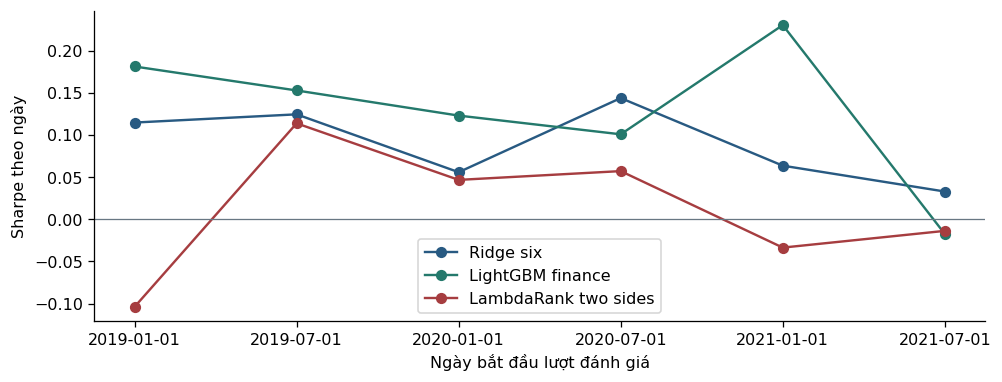

,Sharpe kiểu JPX,Spread (bps/phiên),IC,Phiên chấm chung,Phiên chấm riêng
Mô hình,,,,,
LightGBM finance,0.1252,6.0520,-0.0006,700,700
LightGBM tuned,0.1038,4.6867,-0.0006,700,700
OLS log OHLCV,0.0964,8.6179,-0.0087,700,700
XGBoost tuned,0.0949,4.8791,-0.0019,700,700
LightGBM OHLCV + trend,0.0899,7.2854,-0.0024,700,700
LightGBM early stop,0.0857,4.3643,-0.0020,700,700
Ridge short guard,0.0810,10.9317,-0.0073,700,700
Elastic Net,0.0791,10.7188,-0.0061,700,700
LightGBM OHLCV,0.0775,3.7752,-0.0019,700,700


In [2]:
summary = pd.read_csv(results / "development_summary.csv").set_index("Model")
folds = pd.read_csv(results / "development_folds.csv").set_index("Fold")
selection = json.loads((results / "selected_model.json").read_text(encoding="utf-8"))
baseline, winner = selection["baseline"], selection["name"]
featured = list(dict.fromkeys([baseline, winner, "LightGBM finance", "LambdaRank two sides"]))
colors = {baseline: blue, winner: green, "LightGBM finance": green, "LambdaRank two sides": red}
ax = folds[featured].plot(marker="o", figsize=(10, 3.5), color=[colors[name] for name in featured])
ax.axhline(0, color=gray, linewidth=.8)
ax.set(xlabel="Ngày bắt đầu lượt đánh giá", ylabel="Sharpe theo ngày")
plt.show()
score_columns = {"JPX Sharpe": "Sharpe kiểu JPX", "Spread bps": "Spread (bps/phiên)", "IC": "IC",
                 "Common score sessions": "Phiên chấm chung", "Native score sessions": "Phiên chấm riêng"}
metrics = list(score_columns)
display(summary.loc[summary["Candidate"], metrics].rename(columns=score_columns).rename_axis("Mô hình").round(4))


- Ba đường trong biểu đồ đều là validation. LightGBM finance được chọn, Ridge six là đối chứng, còn LambdaRank minh họa cách học thứ hạng trực tiếp.
- So ứng viên trên cột **Phiên chấm chung**. Cột **Phiên chấm riêng** cho biết độ phủ của từng ứng viên.

## Đối chứng kinh tế và hình dạng tín hiệu

,Sharpe kiểu JPX,Spread (bps/phiên),IC,Phiên chấm chung,Phiên chấm riêng
Mô hình,,,,,
Ridge six,0.0788,10.7959,-0.0071,698,698
LightGBM finance,0.1303,6.2603,-0.0005,698,698
Intraday reversal,0.0546,5.2216,0.0042,698,698
One-session reversal,0.0359,3.6919,0.0044,698,698
20-session momentum,-0.0070,-0.8542,-0.0058,698,698


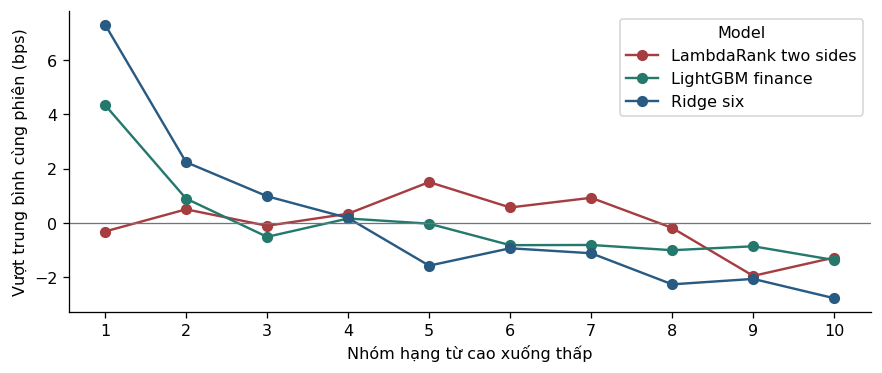

,Vượt trung bình của vế mua (bps),Vượt trung bình của vế bán khống (bps),Tổng 5 khoản lỗ lớn ở vế bán khống (bps)
Mô hình,,,
LambdaRank two sides,-0.22,1.29,14.26
LightGBM finance,4.71,1.34,16.90
Ridge six,7.53,2.86,15.48


In [3]:
matched = pd.read_csv(results / "matched_summary.csv").set_index("Model")
rules = [baseline, winner, "Intraday reversal", "One-session reversal", "20-session momentum"]
display(matched.loc[list(dict.fromkeys(rules)), metrics].rename(columns=score_columns).rename_axis("Mô hình").round(4))
daily = pd.read_csv(results / "development_daily.csv", parse_dates=["Date"])
candidates = summary.index[summary["Candidate"]]
grid = daily.pivot(index="Date", columns="Model", values="Spread")
dates = grid.index[grid[candidates].notna().all(axis=1)]
selected = daily.loc[daily["Date"].isin(dates) & daily["Model"].isin(featured)]
deciles = [f"Decile {i}" for i in range(1, 11)]
curve = selected.groupby("Model")[deciles].mean().T.mul(10_000)
curve.index = range(1, 11)
ax = curve.plot(marker="o", figsize=(9, 3.4), color=[colors[name] for name in curve])
ax.set_xticks(range(1, 11))
ax.axhline(0, color=gray, linewidth=.8)
ax.set(xlabel="Nhóm hạng từ cao xuống thấp", ylabel="Vượt trung bình cùng phiên (bps)")
plt.show()
legs = {"Long excess": "Vượt trung bình của vế mua (bps)",
        "Short excess": "Vượt trung bình của vế bán khống (bps)",
        "Short top five loss": "Tổng 5 khoản lỗ lớn ở vế bán khống (bps)"}
display(selected.groupby("Model")[list(legs)].mean().mul(10_000)
        .rename(columns=legs).rename_axis("Mô hình").round(2))


Hai quy tắc 1 và 20 phiên cần đủ lịch sử. Chúng được so trên cùng rổ mã đủ điều kiện với Ridge và các ứng viên. Đường cong nhóm hạng trả lời liệu tín hiệu trải đều trên bảng hay chỉ xuất hiện ở một trong hai vế. Phân rã lấy trung bình cùng phiên làm mốc và đo riêng năm khoản lỗ lớn ở vế bán.

Ở lượt này, nhóm hạng 1 vượt trung bình phiên ở cả Ridge và LightGBM tài chính. LambdaRank đạt IC trung bình dương nhẹ, trong khi Sharpe chỉ 0,0198 trên cùng 700 phiên. Tối ưu thứ tự theo nhãn phân vị vẫn có thể tạo danh mục hai đầu có spread yếu.

## Độ bất định, sự cố và chế độ thị trường

,Mô hình,Khối (phiên),Cận dưới 95%,Cận trên 95%,Cận dưới đồng thời,Cận trên đồng thời,Phiên chấm chung
16,LightGBM finance,5,-0.0234,0.1337,-0.0854,0.1823,700
21,LambdaRank two sides,5,-0.1245,0.0200,-0.1908,0.0769,700
25,GRU,5,-0.0940,0.0242,-0.1730,0.0947,700
42,LightGBM finance,10,-0.0371,0.1351,-0.0850,0.1819,700
47,LambdaRank two sides,10,-0.1270,0.0194,-0.1904,0.0765,700
51,GRU,10,-0.0877,0.0267,-0.1726,0.0943,700
68,LightGBM finance,20,-0.0421,0.1266,-0.0893,0.1862,700
73,LambdaRank two sides,20,-0.1384,0.0018,-0.1947,0.0808,700
77,GRU,20,-0.0915,0.0165,-0.1769,0.0986,700


,Kịch bản,Số phiên,Sharpe kiểu JPX,Spread (bps/phiên)
0,Ridge gốc,700,0.0768,10.3911
1,Ridge bỏ hai ngày chấm bị ảnh hưởng,698,0.0768,10.3989
2,Ridge gốc trên mẫu so sánh với lượt huấn luyện...,700,0.0768,10.3911
3,Ridge bỏ nhãn bị ảnh hưởng khi huấn luyện,700,0.0760,10.2808


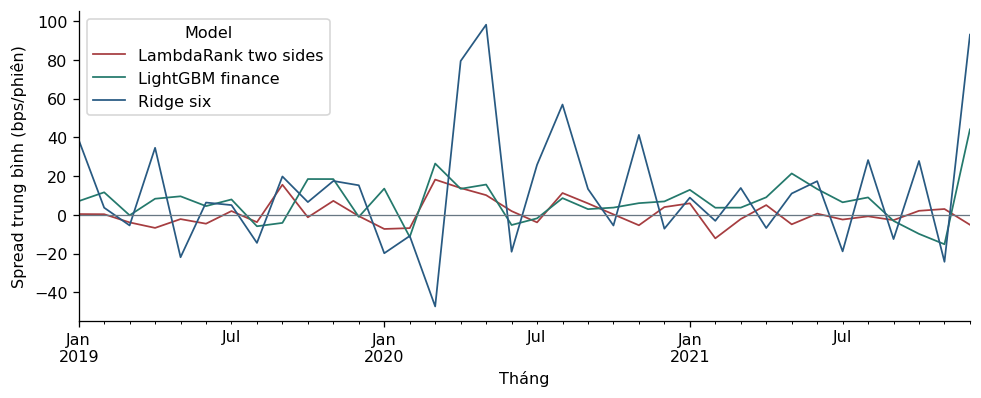

Số phiên  Spread (bps/phiên)
Mô hình              Độ phân tán                                
LambdaRank two sides Cao                 433                1.98
                     Thiếu dữ liệu         1              -39.94
                     Thấp                266               -0.24
LightGBM finance     Cao                 433                6.60
                     Thiếu dữ liệu         1              -10.63
                     Thấp                266                5.22
Ridge six            Cao                 433               13.23
                     Thiếu dữ liệu         1               34.22
                     Thấp                266                5.69

,Phiên đo được,Beta chênh lệch trung bình,Độ lệch chuẩn beta
Mô hình,,,
LightGBM finance,182,-0.009,0.094
Ridge six,1,0.639,NaN


In [4]:
ci = pd.read_csv(results / "sharpe_intervals.csv")
chosen = list(dict.fromkeys([winner, "LightGBM finance", "LambdaRank two sides", "GRU"]))
cols = ["Model", "Block", "Low", "High", "Simultaneous low", "Simultaneous high", "Common score sessions"]
display(ci.loc[ci["Model"].isin(chosen), cols].rename(columns={
    "Model": "Mô hình", "Block": "Khối (phiên)", "Low": "Cận dưới 95%", "High": "Cận trên 95%",
    "Simultaneous low": "Cận dưới đồng thời", "Simultaneous high": "Cận trên đồng thời",
    "Common score sessions": "Phiên chấm chung",
}).round(4))
outage = pd.read_csv(results / "development_outage.csv")
outage["Scenario"] = outage["Scenario"].replace({
    "Ridge original": "Ridge gốc",
    "Ridge remove affected evaluation dates": "Ridge bỏ hai ngày chấm bị ảnh hưởng",
    "Ridge training pair": "Ridge gốc trên mẫu so sánh với lượt huấn luyện lại",
    "Ridge exclude affected training labels": "Ridge bỏ nhãn bị ảnh hưởng khi huấn luyện",
})
display(outage.rename(columns={"Scenario": "Kịch bản", "Sessions": "Số phiên",
                               "JPX Sharpe": "Sharpe kiểu JPX", "Spread bps": "Spread (bps/phiên)"}).round(4))
by_month = selected.groupby([selected["Date"].dt.to_period("M"), "Model"])["Spread"].mean().unstack().mul(10_000)
ax = by_month.plot(figsize=(10, 3.5), linewidth=1.1, color=[colors[name] for name in by_month])
ax.axhline(0, color=gray, linewidth=.8)
ax.set(xlabel="Tháng", ylabel="Spread trung bình (bps/phiên)")
plt.show()
regimes = selected.assign(**{"Độ phân tán": selected["Dispersion regime"].replace(
    {"high": "Cao", "low": "Thấp", "unknown": "Thiếu dữ liệu"},
)})
display(regimes.groupby(["Model", "Độ phân tán"])["Spread"].agg(["size", "mean"])
        .assign(mean=lambda x: x["mean"] * 10_000)
        .rename(columns={"size": "Số phiên", "mean": "Spread (bps/phiên)"})
        .rename_axis(index=["Mô hình", "Độ phân tán"]).round(2))
beta = daily.dropna(subset=["Net beta"]).groupby("Model")["Net beta"].agg(["count", "mean", "std"])
display(beta.rename(columns={"count": "Phiên đo được", "mean": "Beta chênh lệch trung bình",
                             "std": "Độ lệch chuẩn beta"}).rename_axis("Mô hình").round(3))


Bootstrap rút lại các khối từ lịch gốc và ghép cùng phiên giữa các mô hình. Số phiên thiếu vẫn chiếm một vị trí trên lịch. Khoảng đồng thời rộng hơn vì xem nhiều chênh lệch cùng lúc. Bảng sự cố tách ảnh hưởng của việc loại ngày chấm khỏi ảnh hưởng của việc fit lại. Ngưỡng phân tán được tính riêng từ train của mỗi lượt.

## Hoán vị đặc trưng và mạng nơ-ron

,Giảm Sharpe trung bình,Phiên chung nhỏ nhất
LightGBM finance,,
Financial,0.0811,106
margin_report_age,0.0683,106
OHLCV,0.0634,106
Close,0.0546,106
Low,0.0439,106
Volume,0.0322,106


,Giảm Sharpe trung bình,Phiên chung nhỏ nhất
Ridge six,,
volatility_20,0.0365,106
return_20,0.0171,106
intraday_range,0.0086,106
return_1,0.0031,106
relative_turnover_20,0.0004,106
return_5,-0.0062,106


Giảm Sharpe trung bình  Phiên chung nhỏ nhất
Mô hình          Nhóm đặc trưng                                              
LightGBM finance Financial                       0.0353                   106
                 OHLCV                           0.0808                   106

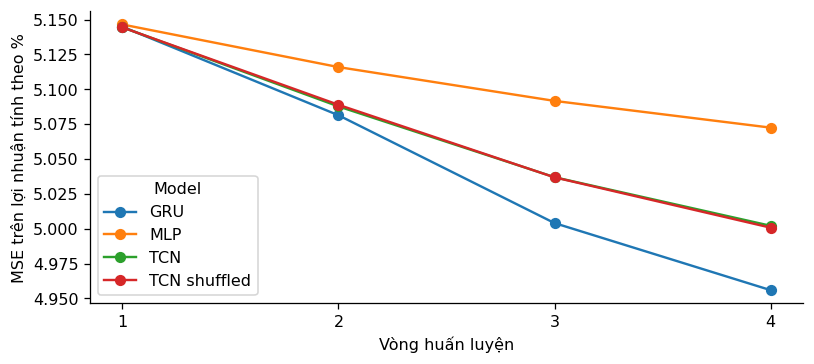

,Phiên,Spread (bps/phiên),Sharpe
Mô hình và seed,,,
GRU,700,4.0004,0.0377
GRU seed 19,700,3.7522,0.0365
GRU seed 37,700,1.3189,0.0127
GRU seed 7,700,4.0128,0.0389
MLP,700,-0.0101,-0.0001
MLP seed 19,700,1.0168,0.0100
MLP seed 37,700,-1.2617,-0.0128
MLP seed 7,700,0.6093,0.0058
TCN,700,0.9874,0.0098


In [5]:
importance = pd.read_csv(results / "importance.csv")
rows = importance.query("Method == 'Permutation' and Metric == 'Spread'")
for model, values in rows.groupby("Model"):
    display(values.groupby("Feature").agg(**{"Giảm Sharpe trung bình": ("Decrease", "mean"),
                                             "Phiên chung nhỏ nhất": ("Common sessions", "min")})
            .sort_values("Giảm Sharpe trung bình", ascending=False).head(6).round(4).rename_axis(model))
display(importance.query("Method == 'Refit without group'").groupby(["Model", "Feature"])
        .agg(**{"Giảm Sharpe trung bình": ("Decrease", "mean"),
                "Phiên chung nhỏ nhất": ("Common sessions", "min")})
        .rename_axis(index=["Mô hình", "Nhóm đặc trưng"]).round(4))
learning = pd.read_csv(results / "development_learning.csv")
curves = learning.groupby(["Epoch", "Model"])["Training MSE percent squared"].mean().unstack()
ax = curves.plot(marker="o", figsize=(8, 3.3))
ax.set_xticks(curves.index)
ax.set(xlabel="Vòng huấn luyện", ylabel="MSE trên lợi nhuận tính theo %")
plt.show()
neural = daily.loc[daily["Model"].str.contains(r"^(?:MLP|GRU|TCN)")]
metrics = neural.groupby("Model")["Spread"].agg(["count", "mean", "std"])
display(pd.DataFrame({"Phiên": metrics["count"], "Spread (bps/phiên)": metrics["mean"] * 10_000, "Sharpe": metrics["mean"] / metrics["std"]}).rename_axis("Mô hình và seed").round(4))


Hoán vị được làm trong cùng ngày. Mức giảm Sharpe có thể phụ thuộc vào thông tin mà nhiều biến cùng mang. Đường học dùng mất mát hồi quy trên train. Bảng dưới đường học giữ kết quả từng seed trên validation và cho phép đối chiếu TCN gốc với TCN bị tráo lịch sử.

## Tìm tham số trong train

In [6]:
tuning = []
for folder in sorted((results / "folds").iterdir()):
    ledger = json.loads((folder / "done.json").read_text(encoding="utf-8"))
    for entry in ledger["candidates"]:
        trials = entry["trials"]
        if trials:
            tested = [trial["sharpe"] for trial in trials if trial["sharpe"] is not None]
            tuning.append({"Lượt": folder.name, "Mô hình": entry["model"],
                           "Số phương án": len(trials), "Phiên đánh giá trong train": trials[0]["sessions"],
                           "Sharpe phương án đầu": trials[0]["sharpe"],
                           "Sharpe cao nhất": max(tested, default=float("nan")),
                           "Tham số huấn luyện lại": entry["params"]})
display(pd.DataFrame(tuning).round(4))


,Lượt,Mô hình,Số phương án,Phiên đánh giá trong train,Sharpe phương án đầu,Sharpe cao nhất,Tham số huấn luyện lại
0,2019-01-01,Ridge tuned,3,118,-0.0561,-0.0339,{'alpha': 1000000}
1,2019-01-01,Elastic Net,3,118,-0.0550,-0.0463,{'alpha': 0.0001}
2,2019-01-01,LightGBM tuned,4,118,0.0353,0.0670,"{'num_leaves': 31, 'min_child_samples': 1000}"
3,2019-01-01,XGBoost tuned,4,118,0.0186,0.0186,"{'max_depth': 3, 'min_child_weight': 50}"
4,2019-01-01,LightGBM early stop,2,118,0.0353,0.0353,{}
5,2019-01-01,XGBoost early stop,2,118,0.0186,0.0186,"{'max_depth': 3, 'min_child_weight': 50}"
6,2019-01-01,Ridge short guard,4,118,-0.0561,-0.0556,{'penalty': 1.0}
7,2019-07-01,Ridge tuned,3,118,-0.0965,-0.0965,{'alpha': 10000}
8,2019-07-01,Elastic Net,3,118,-0.0973,-0.0973,{'alpha': 1e-06}
9,2019-07-01,LightGBM tuned,4,118,0.1964,0.2032,"{'num_leaves': 31, 'min_child_samples': 1000}"


Hai đoạn đánh giá này đều nằm bên trong train của từng lượt. Vì phép tìm tham số đã xem các đoạn đó, chênh lệch giữa phương án đầu trong lưới và phương án cao điểm nhất chỉ mô tả kết quả tìm kiếm. Bảng sáu lượt ở đầu notebook đo mô hình khi dự báo trên cửa sổ kế tiếp.